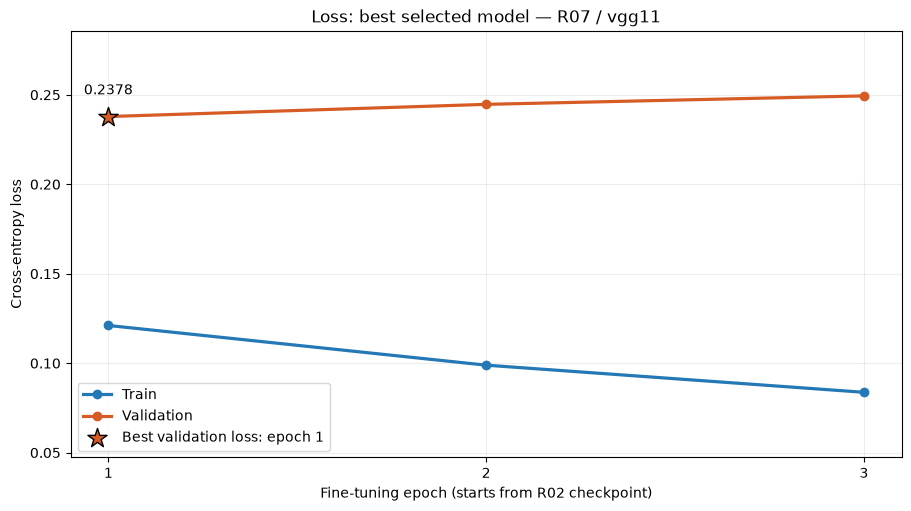

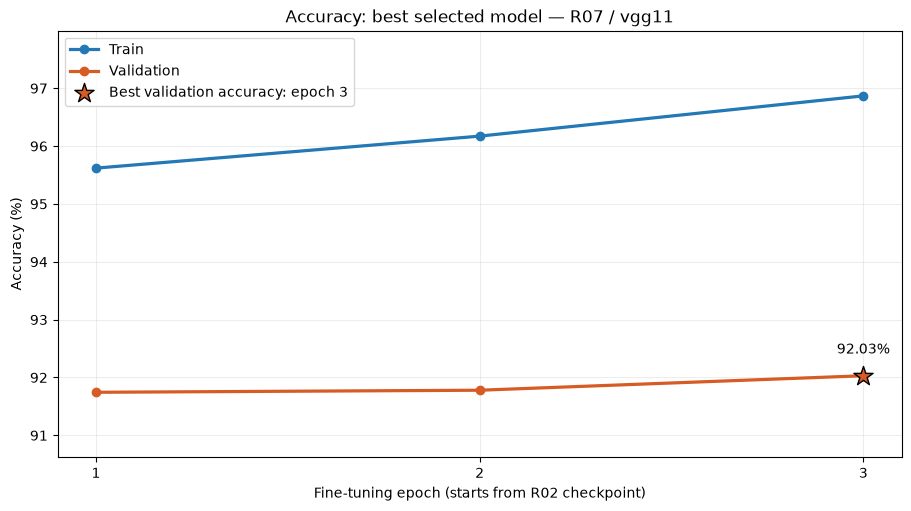

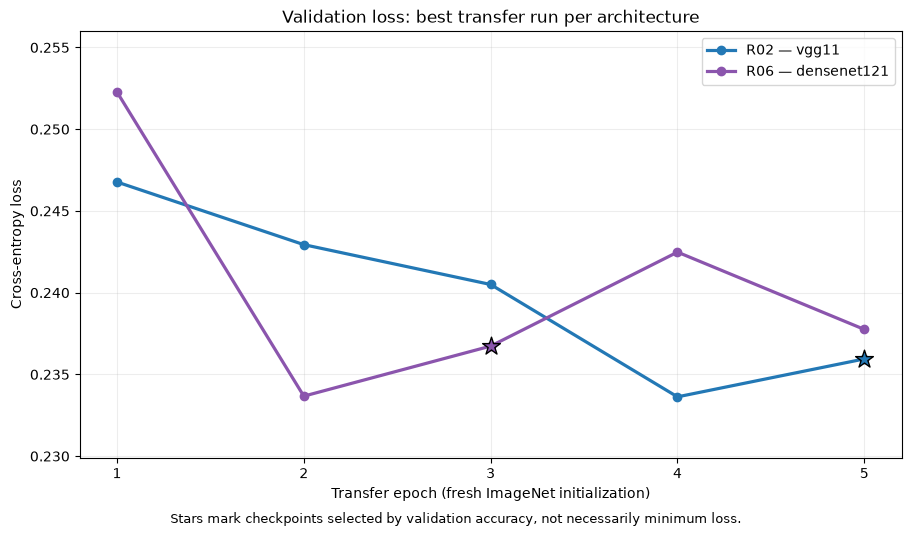

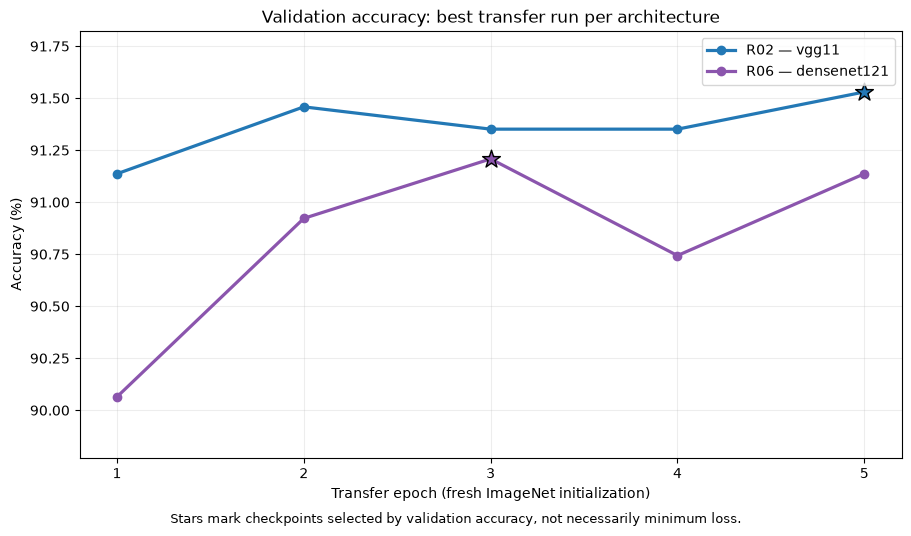

Selected final: R07 | best transfer: ['R02', 'R06']
PNG files:
D:\Lab2\outputs\pipeline_16_steps\best_curves\01_best_model_loss.png
D:\Lab2\outputs\pipeline_16_steps\best_curves\02_best_model_accuracy.png
D:\Lab2\outputs\pipeline_16_steps\best_curves\03_best_transfer_val_loss.png
D:\Lab2\outputs\pipeline_16_steps\best_curves\04_best_transfer_val_accuracy.png


In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

chart_cwd = Path.cwd().resolve()
chart_root = next(p for p in (chart_cwd, *chart_cwd.parents) if (p / 'configs/experiments.json').exists())
chart_out = chart_root / 'outputs/pipeline_16_steps/best_curves'
chart_out.mkdir(parents=True, exist_ok=True)
def chart_json(path):
    return json.loads(path.read_text(encoding='utf-8'))
chart_selection = chart_json(chart_root / 'outputs/experiments/selection.json')
chart_runs = [chart_json(chart_root / f'outputs/experiments/R{i:02d}/result.json') for i in range(1,8)]
def chart_rank(r):
    b=r['best']
    return (-b['val_accuracy'],b['val_loss'],b['epoch'],r['id'])
chart_final = min(chart_runs,key=chart_rank)
assert chart_final['id'] == chart_selection['final_run']
chart_transfer = [min([r for r in chart_runs if r['spec']['mode']=='transfer' and r['spec']['model']==name],key=chart_rank)
                  for name in ('vgg11','densenet121')]
assert {r['spec']['model']:r['id'] for r in chart_transfer} == chart_selection['best_transfer_per_model']
chart_history = chart_final['history']
chart_epochs = [r['epoch'] for r in chart_history]
chart_files = []

for metric,title,ylabel,filename in [
    ('loss','Loss: best selected model','Cross-entropy loss','01_best_model_loss.png'),
    ('accuracy','Accuracy: best selected model','Accuracy (%)','02_best_model_accuracy.png')]:
    fig,ax=plt.subplots(figsize=(9,5),layout='constrained')
    scale=100 if metric=='accuracy' else 1
    for prefix,label,color in [('train','Train','#2378b5'),('val','Validation','#d65b24')]:
        ax.plot(chart_epochs,[row[f'{prefix}_{metric}']*scale for row in chart_history],
                marker='o',linewidth=2.3,label=label,color=color)
    optimum=(min if metric=='loss' else max)(chart_history,key=lambda row:row[f'val_{metric}'])
    x,y=optimum['epoch'],optimum[f'val_{metric}']*scale
    ax.scatter([x],[y],marker='*',s=210,color='#d65b24',edgecolor='black',zorder=5,
               label=f'Best validation {metric}: epoch {x}')
    ax.annotate(f'{y:.4f}' if metric=='loss' else f'{y:.2f}%',(x,y),xytext=(0,16),
                textcoords='offset points',ha='center')
    ax.set(title=f"{title} — {chart_final['id']} / {chart_final['spec']['model']}",
           xlabel='Fine-tuning epoch (starts from R02 checkpoint)',ylabel=ylabel,xticks=chart_epochs)
    ax.grid(alpha=.22);ax.margins(y=.22);ax.legend(loc='best')
    path=chart_out/filename;fig.savefig(path,dpi=160);chart_files.append(str(path))
    display(fig);plt.close(fig)

for metric,title,ylabel,filename in [
    ('val_loss','Validation loss: best transfer run per architecture','Cross-entropy loss','03_best_transfer_val_loss.png'),
    ('val_accuracy','Validation accuracy: best transfer run per architecture','Accuracy (%)','04_best_transfer_val_accuracy.png')]:
    fig,ax=plt.subplots(figsize=(9,5),layout='constrained')
    scale=100 if metric=='val_accuracy' else 1
    for result,color in zip(chart_transfer,['#2378b5','#8b55ad']):
        history=result['history'];xx=[r['epoch'] for r in history]; yy=[r[metric]*scale for r in history]
        ax.plot(xx,yy,marker='o',linewidth=2.3,color=color,label=f"{result['id']} — {result['spec']['model']}")
        chosen=result['best'];ax.scatter([chosen['epoch']],[chosen[metric]*scale],marker='*',s=180,
                                        color=color,edgecolor='black',zorder=5)
    ax.set(title=title,xlabel='Transfer epoch (fresh ImageNet initialization)',ylabel=ylabel,xticks=range(1,6))
    ax.grid(alpha=.22);ax.margins(y=.2);ax.legend(loc='best')
    fig.text(.5,-.035,'Stars mark checkpoints selected by validation accuracy, not necessarily minimum loss.',
             ha='center',fontsize=9)
    path=chart_out/filename;fig.savefig(path,dpi=160,bbox_inches='tight');chart_files.append(str(path))
    display(fig);plt.close(fig)
print('Selected final:',chart_final['id'],'| best transfer:',[r['id'] for r in chart_transfer])
print('PNG files:',*chart_files,sep='\n')
